In [1]:
import torch
torch.__version__

'2.14.0+cu130'

In [3]:
l = torch.nn.Linear(384, 384)
l.weight.shape

torch.Size([384, 384])

In [4]:
l.in_features, l.out_features

(384, 384)

In [6]:
import torch.nn as nn

class LoRALinear(nn.Module):
    def __init__(self, original, rank=4):
        super().__init__()

        # 기존 Linear Layer
        self.original = original

        # 기존 가중치 고정
        for param in self.original.parameters():
            param.requires_grad = False

        in_dim = original.in_features
        out_dim = original.out_features

        # LoRA 추가 행렬
        self.lora_A = nn.Linear(in_dim, rank, bias=False)
        self.lora_B = nn.Linear(rank, out_dim, bias=False)

        # 처음에는 LoRA 효과가 0이 되도록 초기화
        nn.init.kaiming_uniform_(self.lora_A.weight, a=5**0.5)
        nn.init.zeros_(self.lora_B.weight)

    def forward(self, x):
        original_output = self.original(x)
        lora_output = self.lora_B(self.lora_A(x))

        return original_output + lora_output


# 기존 Linear
linear = nn.Linear(768, 768)

# LoRA 적용
lora_linear = LoRALinear(linear, rank=4)

x = torch.randn(2, 10, 768)
y = lora_linear(x)

print(y.shape)  # (2, 10, 768)


torch.Size([2, 10, 768])


In [7]:
for n, p in lora_linear.named_parameters():
  print(n, p.shape)

original.weight torch.Size([768, 768])
original.bias torch.Size([768])
lora_A.weight torch.Size([4, 768])
lora_B.weight torch.Size([768, 4])


In [26]:
import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to("cuda")

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [33]:
image = pipe(
    "a guy",
    generator=torch.Generator(device="cuda").manual_seed(42)
).images[0]

image.save("guy-42-2.png")

  0%|          | 0/50 [00:00<?, ?it/s]

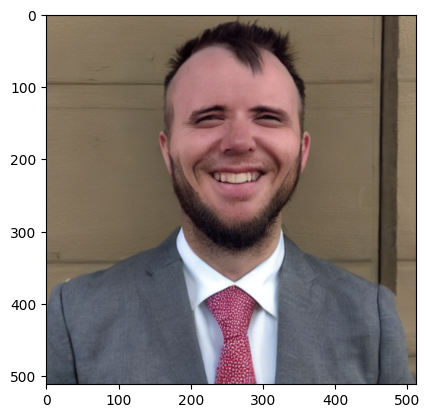

In [25]:
import cv2
import torch

cat = cv2.imread("./cat-1.png")
cat = cv2.cvtColor(cat, cv2.COLOR_BGR2RGB)
cat = torch.from_numpy(cat)
cat.permute(2, 0, 1).shape

import matplotlib.pyplot as plt
plt.imshow(cat)

In [11]:
import torch
from diffusers import DDPMPipeline

pipe = DDPMPipeline.from_pretrained(
    "google/ddpm-cifar10-32"
).to("cuda")

image = pipe().images[0]
image.save("random.png")

model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hurwa\.cache\huggingface\hub\models--google--ddpm-cifar10-32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [83]:
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
)

pipe = pipe.to("cuda")

image = pipe(
    prompt="cat lying on a grass",
    num_inference_steps=25,
    guidance_scale=7.5,
    height=512,
    width=512,
).images[0]

image.save("cat.png")

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

In [30]:
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.get_device_name(0))

2.14.0+cu130
13.0
NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [47]:
q_counter = 0
k_counter = 0
for name, module in pipe.unet.named_modules():
    if "to_k" in name:
      k_counter += 1
      print(name, type(module))
    if "to_q" in name:
      q_counter += 1
      print(name, type(module))

print("q_counter:", q_counter)
print("k_counter:", k_counter)

down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_q <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_k <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_q <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_k <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.1.transformer_blocks.0.attn1.to_q <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.1.transformer_blocks.0.attn1.to_k <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.1.transformer_blocks.0.attn2.to_q <class 'torch.nn.modules.linear.Linear'>
down_blocks.0.attentions.1.transformer_blocks.0.attn2.to_k <class 'torch.nn.modules.linear.Linear'>
down_blocks.1.attentions.0.transformer_blocks.0.attn1.to_q <class 'torch.nn.modules.linear.Linear'>
down_blocks.1.attentions.0.transformer_blocks.0.attn1.to_k <class 'torch.nn.modules.linear.Linear'>


In [41]:
for name, module in pipe.vae.named_modules():
    print(name, type(module))

 <class 'diffusers.models.autoencoders.autoencoder_kl.AutoencoderKL'>
encoder <class 'diffusers.models.autoencoders.vae.Encoder'>
encoder.conv_in <class 'torch.nn.modules.conv.Conv2d'>
encoder.down_blocks <class 'torch.nn.modules.container.ModuleList'>
encoder.down_blocks.0 <class 'diffusers.models.unets.unet_2d_blocks.DownEncoderBlock2D'>
encoder.down_blocks.0.resnets <class 'torch.nn.modules.container.ModuleList'>
encoder.down_blocks.0.resnets.0 <class 'diffusers.models.resnet.ResnetBlock2D'>
encoder.down_blocks.0.resnets.0.norm1 <class 'torch.nn.modules.normalization.GroupNorm'>
encoder.down_blocks.0.resnets.0.conv1 <class 'torch.nn.modules.conv.Conv2d'>
encoder.down_blocks.0.resnets.0.norm2 <class 'torch.nn.modules.normalization.GroupNorm'>
encoder.down_blocks.0.resnets.0.dropout <class 'torch.nn.modules.dropout.Dropout'>
encoder.down_blocks.0.resnets.0.conv2 <class 'torch.nn.modules.conv.Conv2d'>
encoder.down_blocks.0.resnets.0.nonlinearity <class 'torch.nn.modules.activation.SiLU

In [53]:
pipe.tokenizer.model_max_length

77

In [56]:
tokens = pipe.tokenizer("안녕하세요",)
type(tokens), str(tokens), repr(tokens)

(transformers.tokenization_utils_base.BatchEncoding,
 "{'input_ids': [49406, 16071, 230, 167, 227, 243, 33992, 15074, 116, 18541, 498, 49407], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}",
 "{'input_ids': [49406, 16071, 230, 167, 227, 243, 33992, 15074, 116, 18541, 498, 49407], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}")

In [ ]:

with torch.inference_mode():
    # 1. 텍스트 → Token ID
    tokens = pipe.tokenizer(
        "안녕하세요",
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt"
    )

    # 2. Token ID를 GPU로 이동
    input_ids = tokens.input_ids.to("cuda")

    # 3. Token ID → Text Embedding
    result = pipe.text_encoder(input_ids)

    # 4. Unet
    pipe.scheduler.set_timesteps(25, device=pipe.device)

    noise_img = torch.randn((1, 4, 64, 64), device="cuda", dtype=torch.float16)

    result = pipe.unet(
        sample=noise_img,
        timestep=pipe.scheduler.timesteps[0],
        encoder_hidden_states=result["last_hidden_state"]
    )

    result = pipe.vae(sample=result["sample"])
    # 어떤 scheduler는 초기 noise sigma를 곱해줘야 함
    if hasattr(pipe.scheduler, "init_noise_sigma"):
        latents = latents * pipe.scheduler.init_noise_sigma

    # 4) denoising loop
    for t in pipe.scheduler.timesteps:
        noise_pred = pipe.unet(
            latents,
            t,
            encoder_hidden_states=text_embeddings
        ).sample

        latents = pipe.scheduler.step(
            noise_pred,
            t,
            latents
        ).prev_sample

    # 5) 마지막 latent를 VAE로 decode
    latents = latents / pipe.vae.config.scaling_factor
    image = pipe.vae.decode(latents).sample

    # 6) [-1, 1] -> [0, 1]
    image = (image / 2 + 0.5).clamp(0, 1)

    # 7) Tensor -> PIL
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    pil_image = pipe.numpy_to_pil(image)[0]
  # pipe.unet()
  # pipe.scheduler()
  # pipe.vae()

# text encoder
# print(result["last_hidden_state"].shape)#["pooler_output"].shape)

# unet
# print(result["sample"].shape)

# vae
print(result)

RuntimeError: Given groups=1, weight of size [128, 3, 3, 3], expected input[1, 4, 64, 64] to have 3 channels, but got 4 channels instead

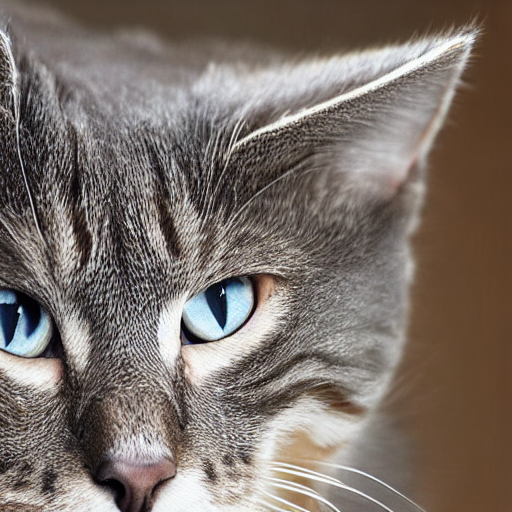

In [96]:
import copy
import torch

# # Scheduler 상태 백업
# original_scheduler = copy.deepcopy(pipe.scheduler)

# def generate(seed=42):
#     return pipe(
#         "a realistic photo of a cat sitting on grass",
#         num_inference_steps=25,
#         guidance_scale=7.5,
#         generator=torch.Generator(
#             device="cuda"
#         ).manual_seed(seed)
#     ).images[0]

# # 첫 번째 생성
# image1 = generate()
# image1.save("before.png")


import torch

prompt = "cat"
device = pipe._execution_device
dtype = pipe.unet.dtype

# generator = torch.Generator(device=device).manual_seed(42)

with torch.inference_mode():
    # 1. Positive / Negative Prompt 인코딩
    texts = ["", prompt]

    tokens = pipe.tokenizer(
        texts,
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt"
    )

    text_embeddings = pipe.text_encoder(
        tokens.input_ids.to(device)
    ).last_hidden_state.to(dtype=dtype)

    # 2. Scheduler 설정
    pipe.scheduler.set_timesteps(25, device=device)

    # 3. 초기 노이즈
    latents = torch.randn(
        (1, 4, 64, 64),
        # generator=generator,
        device=device,
        dtype=dtype
    )
    latents = latents * pipe.scheduler.init_noise_sigma

    # 4. Denoising
    for t in pipe.scheduler.timesteps:
        latent_input = torch.cat([latents, latents])

        latent_input = pipe.scheduler.scale_model_input(
            latent_input, t
        )

        noise_pred = pipe.unet(
            latent_input,
            t,
            encoder_hidden_states=text_embeddings
        ).sample

        noise_uncond, noise_text = noise_pred.chunk(2)

        # CFG
        guidance_scale = 7.5
        noise_pred = noise_uncond + guidance_scale * (
            noise_text - noise_uncond
        )

        latents = pipe.scheduler.step(
            noise_pred, t, latents
        ).prev_sample

    # 5. VAE Decode
    latents = latents / pipe.vae.config.scaling_factor

    image = pipe.vae.decode(
        latents.to(dtype=pipe.vae.dtype)
    ).sample

    # 6. Tensor -> Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(
        0, 2, 3, 1
    ).float().numpy()

    pil_image = pipe.numpy_to_pil(image)[0]

pil_image.save("manual_fixed.png")
pil_image


# # Scheduler 원래 상태 복원
# pipe.scheduler = original_scheduler

# # 같은 Seed로 다시 생성
# image2 = generate()
# image2.save("after.png")

In [59]:
pipe.scheduler.timesteps[0]

tensor(961, device='cuda:0')

In [58]:
# SD 1.5, 512x512 기준
latents = torch.randn(
    (1, 4, 64, 64),
    device="cuda",
    dtype=torch.float16
)

pipe.scheduler.set_timesteps(25, device="cuda")
t = pipe.scheduler.timesteps[0]

with torch.inference_mode():
    noise_pred = pipe.unet(
        latents,
        t,
        encoder_hidden_states=result.last_hidden_state
    ).sample

print(noise_pred.shape)
# torch.Size([1, 4, 64, 64])

torch.Size([1, 4, 64, 64])
